# S4 - ML distribuido con Spark MLlib: regresión de la temperatura mínima nocturna
**Proyecto Sello · Equipo 10 BIG IMPACT · Predicción de heladas en Juliaca**

## Fase 1 — Business Understanding

**Objetivo:** estimar `temp_min_noche` (la temperatura mínima entre las 19:00 de un día y las 09:00 del siguiente) a partir de lo que se mide a las **18:00** de ese día: temperatura, punto de rocío, humedad y nubosidad, más la estacionalidad (día del año). No es un modelo con historial temporal; eso es contenido de la serie de tiempo de U2.

**Decisión de negocio:** el agricultor decide a las 18:00 si cubre sus cultivos. Una helada meteorológica ocurre cuando la mínima es ≤ 0 °C, así que si el modelo estima `temp_min_noche` ≤ 0 °C, se recomienda cubrir.

**Alcance:** comparar un modelo base de regresión lineal, tres configuraciones de regularización y un segundo algoritmo (Random Forest), reportando RMSE, R² y MAE, sin búsqueda exhaustiva de hiperparámetros. Después se valida si el error es aceptable para decidir una helada.

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion4-ml-distribuido-regresion")
    .master("local[*]")
    .config("spark.ui.port", "4040")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

spark

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 02:44:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/20 02:44:24 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/20 02:44:24 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/20 02:44:24 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.


### 1.1 Origen de los datos
La entrada es la capa **Gold** construida en S3 (Parquet particionado por `mes`).

In [2]:
ORIGEN_DATOS = "/opt/u1/s03-calidad-particionamiento/artifacts/clima_particionado"
print("Gold (origen):", ORIGEN_DATOS)

Gold (origen): /opt/u1/s03-calidad-particionamiento/artifacts/clima_particionado


### 1.2 Gráfico: qué se quiere predecir
Una noche real con helada. A las 18:00 se conocen las variables; el objetivo es la mínima que ocurrirá de madrugada.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
                                                                                

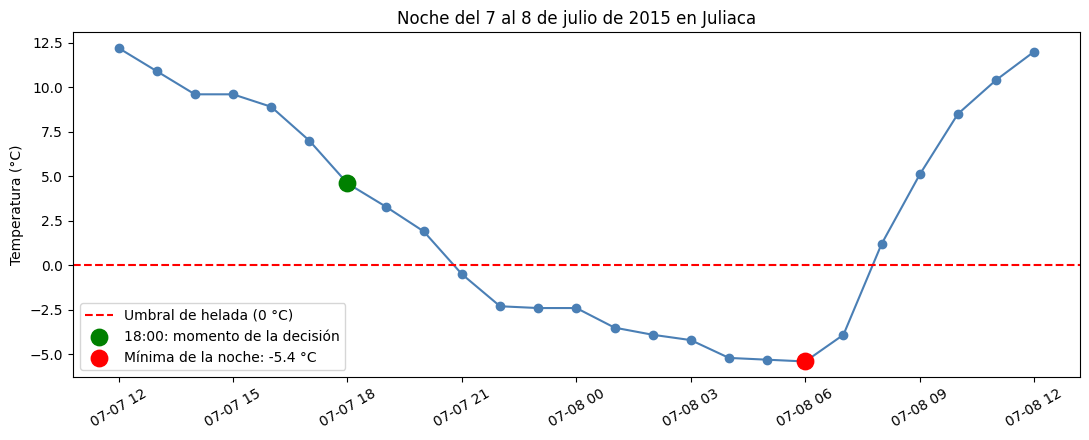

In [3]:
import matplotlib.pyplot as plt
from pyspark.sql.functions import col

df_gold = spark.read.parquet(ORIGEN_DATOS)

noche = (
    df_gold
    .filter((col("hora") >= "2015-07-07 12:00:00") & (col("hora") <= "2015-07-08 12:00:00"))
    .orderBy("hora")
    .select("hora", "temperatura")
    .toPandas()
)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(noche["hora"], noche["temperatura"], marker="o", color="#4a7fb5")
ax.axhline(0, color="red", linestyle="--", label="Umbral de helada (0 °C)")

h18 = noche[noche["hora"].dt.strftime("%Y-%m-%d %H") == "2015-07-07 18"]
ax.scatter(h18["hora"], h18["temperatura"], color="green", s=140, zorder=5, label="18:00: momento de la decisión")

idx_min = noche["temperatura"].idxmin()
ax.scatter(noche.loc[idx_min, "hora"], noche.loc[idx_min, "temperatura"], color="red", s=140, zorder=5,
           label=f"Mínima de la noche: {noche.loc[idx_min, 'temperatura']} °C")

ax.set_title("Noche del 7 al 8 de julio de 2015 en Juliaca")
ax.set_ylabel("Temperatura (°C)")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Fase 2 — Data Understanding
### 2.1 Cargar la capa Gold

In [4]:
from pyspark.sql.functions import col

df_gold = spark.read.parquet(ORIGEN_DATOS)
df_gold.printSchema()
print("Filas Gold:", df_gold.count())

root
 |-- ciudad: string (nullable = true)
 |-- hora: timestamp (nullable = true)
 |-- temperatura: double (nullable = true)
 |-- puntoRocio: double (nullable = true)
 |-- humedad: integer (nullable = true)
 |-- nubosidad: integer (nullable = true)
 |-- presion: double (nullable = true)
 |-- precipitacion: double (nullable = true)
 |-- anio: integer (nullable = true)
 |-- mes: integer (nullable = true)

Filas Gold: 146832


### 2.2 Construir una fila por noche
- **Predictores:** lecturas de las **18:00** del día D (`temp_18`, `rocio_18`, `hum_18`, `nub_18`).
- **Objetivo:** `temp_min_noche` = mínima entre las 19:00 de D y las 09:00 de D+1.
- Se descartan noches incompletas (menos de 15 lecturas) para no calcular la mínima sobre datos faltantes.

In [5]:
from pyspark.sql.functions import hour, to_date, expr, min as fmin, count

# Variables a las 18:00 de cada día
f18 = (
    df_gold.filter(hour("hora") == 18)
    .select(
        to_date("hora").alias("fecha"),
        col("temperatura").alias("temp_18"),
        col("puntoRocio").alias("rocio_18"),
        col("humedad").alias("hum_18"),
        col("nubosidad").alias("nub_18"),
    )
)

# Mínima de la noche: se desplaza la hora 19 h hacia atrás, así las 19:00 de D
# quedan en 00:00 de D y las 09:00 de D+1 en 14:00 de D.
noche = (
    df_gold
    .withColumn("h", expr("hora - INTERVAL 19 HOURS"))
    .filter(hour("h") <= 14)
    .groupBy(to_date("h").alias("fecha"))
    .agg(fmin("temperatura").alias("temp_min_noche"), count("*").alias("horas_noche"))
    .filter(col("horas_noche") == 15)
)

df_noche = f18.join(noche, on="fecha", how="inner").drop("horas_noche").orderBy("fecha")

print("Noches en el dataset:", df_noche.count())
df_noche.show(5)

Noches en el dataset: 6117
+----------+-------+--------+------+------+--------------+
|     fecha|temp_18|rocio_18|hum_18|nub_18|temp_min_noche|
+----------+-------+--------+------+------+--------------+
|2010-01-01|   12.4|     3.6|    63|     5|           4.5|
|2010-01-02|   11.2|     4.5|    66|    89|           5.7|
|2010-01-03|   10.2|     4.9|    72|    79|           5.2|
|2010-01-04|    8.6|     4.9|    81|    70|           5.6|
|2010-01-05|   10.1|     5.2|    78|    79|           3.9|
+----------+-------+--------+------+------+--------------+
only showing top 5 rows


### 2.3 Describir las variables y estadísticas

In [6]:
df_noche.printSchema()
df_noche.select("temp_18", "rocio_18", "hum_18", "nub_18", "temp_min_noche").describe().show()

root
 |-- fecha: date (nullable = true)
 |-- temp_18: double (nullable = true)
 |-- rocio_18: double (nullable = true)
 |-- hum_18: integer (nullable = true)
 |-- nub_18: integer (nullable = true)
 |-- temp_min_noche: double (nullable = true)



26/11/20 02:46:36 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-------+------------------+-------------------+------------------+-----------------+------------------+
|summary|           temp_18|           rocio_18|            hum_18|           nub_18|    temp_min_noche|
+-------+------------------+-------------------+------------------+-----------------+------------------+
|  count|              6117|               6117|              6117|             6117|              6117|
|   mean|10.181608631682199|0.20665358836030823| 59.89880660454471|40.26679744973026|2.8346902076181197|
| stddev|1.9697807314514548|  5.217714255635199|18.450002974508024|35.39450326127168| 2.448912237601169|
|    min|               0.4|              -32.2|                 6|                0|              -5.4|
|    max|              17.3|                7.6|               100|              100|               8.9|
+-------+------------------+-------------------+------------------+-----------------+------------------+



### 2.4 Correlación de cada variable con el objetivo

In [8]:
predictores = ["temp_18", "rocio_18", "hum_18", "nub_18"]

correlaciones = {c: df_noche.stat.corr(c, "temp_min_noche") for c in predictores}
for c, v in correlaciones.items():
    print(f"{c} vs temp_min_noche: {v:.3f}")

temp_18 vs temp_min_noche: 0.212
rocio_18 vs temp_min_noche: 0.758
hum_18 vs temp_min_noche: 0.528
nub_18 vs temp_min_noche: 0.555


### 2.5 Gráficos: relación con el objetivo
Izquierda: temperatura a las 18:00 contra la mínima de la noche; los puntos rojos son noches con helada (mínima ≤ 0 °C). Derecha: correlación de cada predictor.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


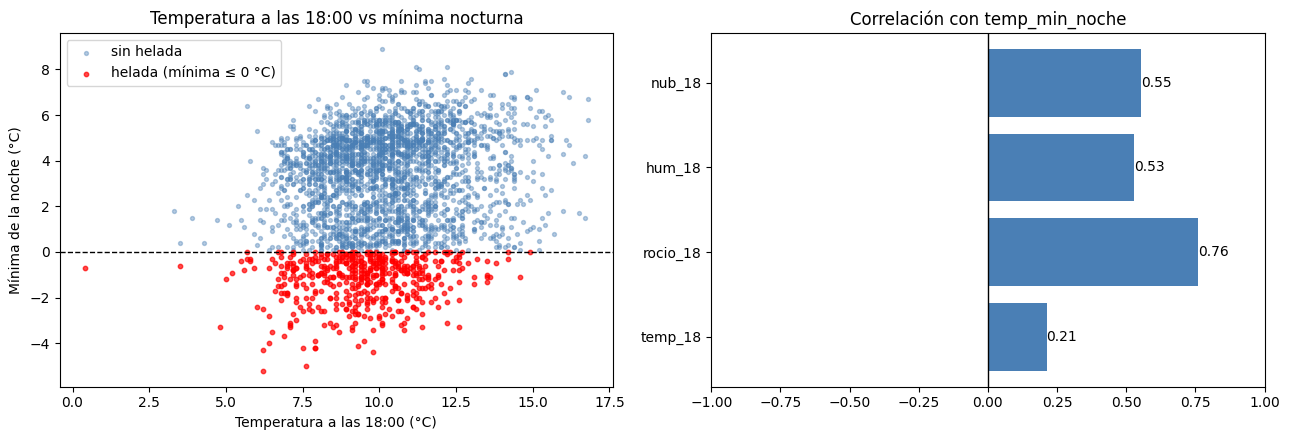

In [9]:
import matplotlib.pyplot as plt

muestra = df_noche.sample(fraction=0.5, seed=42).toPandas()
helada = muestra["temp_min_noche"] <= 0

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

axs[0].scatter(muestra.loc[~helada, "temp_18"], muestra.loc[~helada, "temp_min_noche"], s=8, alpha=0.4, color="#4a7fb5", label="sin helada")
axs[0].scatter(muestra.loc[helada, "temp_18"], muestra.loc[helada, "temp_min_noche"], s=10, alpha=0.7, color="red", label="helada (mínima ≤ 0 °C)")
axs[0].axhline(0, color="black", linestyle="--", linewidth=1)
axs[0].set_xlabel("Temperatura a las 18:00 (°C)")
axs[0].set_ylabel("Mínima de la noche (°C)")
axs[0].set_title("Temperatura a las 18:00 vs mínima nocturna")
axs[0].legend()

nombres = list(correlaciones.keys())
valores = list(correlaciones.values())
colores = ["#4a7fb5" if v >= 0 else "#c0504d" for v in valores]
barras = axs[1].barh(nombres, valores, color=colores)
axs[1].bar_label(barras, fmt="%.2f")
axs[1].axvline(0, color="black", linewidth=1)
axs[1].set_xlim(-1, 1)
axs[1].set_title("Correlación con temp_min_noche")

plt.tight_layout()
plt.show()

## Fase 3 — Data Preparation
### 3.1 Estacionalidad: día del año codificado de forma cíclica
El día 365 está pegado al día 1, pero como número parecen lejanos. Se codifica con seno y coseno para que el modelo entienda que el año es un ciclo.

In [10]:
from pyspark.sql.functions import dayofyear, sin, cos, lit, col
import math

df_modelo = (
    df_noche
    .withColumn("dia_anio", dayofyear("fecha"))
    .withColumn("seno", sin(2 * math.pi * col("dia_anio") / 365.25))
    .withColumn("coseno", cos(2 * math.pi * col("dia_anio") / 365.25))
)

df_modelo.select("fecha", "dia_anio", "seno", "coseno", "temp_min_noche").show(5)

+----------+--------+--------------------+------------------+--------------+
|     fecha|dia_anio|                seno|            coseno|temp_min_noche|
+----------+--------+--------------------+------------------+--------------+
|2010-01-01|       1|0.017201575418260506|0.9998520419557735|           4.5|
|2010-01-02|       2| 0.03439806061360801|0.9994082116062598|           5.7|
|2010-01-03|       3|0.051584366869408364|0.9986686402879997|           5.2|
|2010-01-04|       4| 0.06875540848113941|0.9976335468520451|           5.6|
|2010-01-05|       5| 0.08590610426133272|0.9963032375991965|           3.9|
+----------+--------+--------------------+------------------+--------------+
only showing top 5 rows


### 3.2 Dos conjuntos de predictores a comparar
- **Config A (solo estacionalidad):** `seno`, `coseno`. Es la línea base: ¿cuánto se explica solo con la fecha?
- **Config B (estacionalidad + contexto):** `seno`, `coseno`, `temp_18`, `rocio_18`, `hum_18`, `nub_18`.

`presion` y `precipitacion` quedan fuera: la presión por el sesgo entre fuentes y la lluvia está fuera del proyecto.

In [11]:
predictores_A = ["seno", "coseno"]
predictores_B = ["seno", "coseno", "temp_18", "rocio_18", "hum_18", "nub_18"]

print("Config A:", predictores_A)
print("Config B:", predictores_B)

Config A: ['seno', 'coseno']
Config B: ['seno', 'coseno', 'temp_18', 'rocio_18', 'hum_18', 'nub_18']


### 3.3 Ensamblar el vector de predictores (VectorAssembler)
MLlib espera todos los predictores en **una sola columna de tipo vector**.

In [12]:
from pyspark.ml.feature import VectorAssembler

assembler_A = VectorAssembler(inputCols=predictores_A, outputCol="features_A")
assembler_B = VectorAssembler(inputCols=predictores_B, outputCol="features_B")

df_vec = assembler_B.transform(assembler_A.transform(df_modelo))

df_vec.select("fecha", "features_A", "features_B", "temp_min_noche").show(3, truncate=False)

+----------+-----------------------------------------+------------------------------------------------------------+--------------+
|fecha     |features_A                               |features_B                                                  |temp_min_noche|
+----------+-----------------------------------------+------------------------------------------------------------+--------------+
|2010-01-01|[0.017201575418260506,0.9998520419557735]|[0.017201575418260506,0.9998520419557735,12.4,3.6,63.0,5.0] |4.5           |
|2010-01-02|[0.03439806061360801,0.9994082116062598] |[0.03439806061360801,0.9994082116062598,11.2,4.5,66.0,89.0] |5.7           |
|2010-01-03|[0.051584366869408364,0.9986686402879997]|[0.051584366869408364,0.9986686402879997,10.2,4.9,72.0,79.0]|5.2           |
+----------+-----------------------------------------+------------------------------------------------------------+--------------+
only showing top 3 rows


### 3.4 División aleatoria en entrenamiento (80 %) y prueba (20 %)
Con `seed=42` la división es reproducible. El modelo no ve el conjunto de prueba durante el entrenamiento.

In [13]:
train, test = df_vec.randomSplit([0.8, 0.2], seed=42)

n_train, n_test = train.count(), test.count()
print("Entrenamiento:", n_train, f"({n_train / (n_train + n_test) * 100:.1f}%)")
print("Prueba:       ", n_test, f"({n_test / (n_train + n_test) * 100:.1f}%)")

Entrenamiento: 4942 (80.8%)
Prueba:        1175 (19.2%)


### 3.5 Escalado de predictores (StandardScaler)
Las variables tienen escalas distintas (temperatura en °C, humedad en 0-100). Escalarlas evita que una domine la regularización. Se ajusta **solo con entrenamiento** y se aplica a ambos conjuntos.

In [14]:
from pyspark.ml.feature import StandardScaler

scaler_B = StandardScaler(inputCol="features_B", outputCol="features_B_esc", withMean=True, withStd=True)
scaler_B_modelo = scaler_B.fit(train)

train = scaler_B_modelo.transform(train)
test = scaler_B_modelo.transform(test)

train.select("features_B", "features_B_esc").show(3, truncate=False)

+-----------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------+
|features_B                                                 |features_B_esc                                                                                                        |
+-----------------------------------------------------------+----------------------------------------------------------------------------------------------------------------------+
|[0.017201575418260506,0.9998520419557735,12.4,3.6,63.0,5.0]|[0.014081538948718199,1.4327241709605272,1.1135823607859405,0.6593673740888775,0.1765460996618241,-0.9863019566885596]|
|[0.03439806061360801,0.9994082116062598,11.2,4.5,66.0,89.0]|[0.038410231191380886,1.4320967151965838,0.5075394648793025,0.8314721490045197,0.33886997399275326,1.3803712147374203]|
|[0.06875540848113941,0.9976335468520451,8.6,4.9,81.0,70.0] |[0.08701721878495136,1.42958782045

### 3.6 Gráfico: ¿entrenamiento y prueba son representativos?
Las dos distribuciones del objetivo deben parecerse; si no, la evaluación no sería confiable.

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


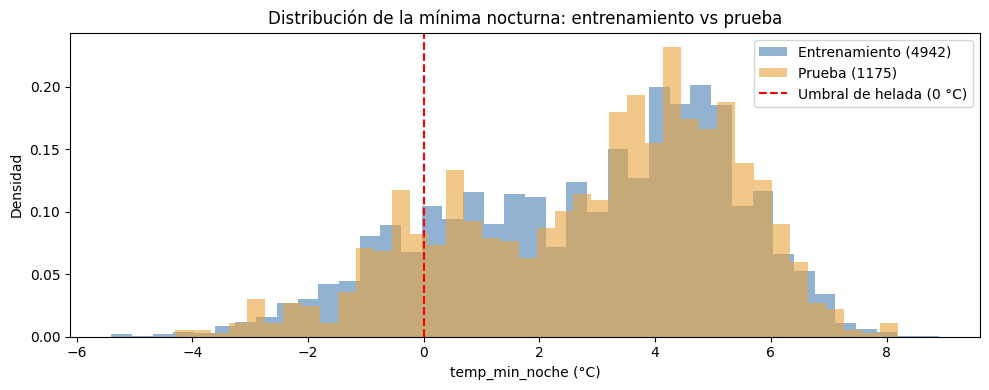

Heladas en entrenamiento: 16.2%
Heladas en prueba:        15.7%


In [15]:
import matplotlib.pyplot as plt

pd_train = train.select("temp_min_noche").toPandas()["temp_min_noche"]
pd_test = test.select("temp_min_noche").toPandas()["temp_min_noche"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(pd_train, bins=40, alpha=0.6, density=True, label=f"Entrenamiento ({len(pd_train)})", color="#4a7fb5")
ax.hist(pd_test, bins=40, alpha=0.6, density=True, label=f"Prueba ({len(pd_test)})", color="#e8a33d")
ax.axvline(0, color="red", linestyle="--", label="Umbral de helada (0 °C)")
ax.set_title("Distribución de la mínima nocturna: entrenamiento vs prueba")
ax.set_xlabel("temp_min_noche (°C)"); ax.set_ylabel("Densidad")
ax.legend()
plt.tight_layout()
plt.show()

print("Heladas en entrenamiento:", f"{(pd_train <= 0).mean() * 100:.1f}%")
print("Heladas en prueba:       ", f"{(pd_test <= 0).mean() * 100:.1f}%")

## Fase 4 — Modeling
### 4.1 Función de evaluación
Se evalúa con las tres métricas de regresión: **RMSE** (error típico en °C, penaliza errores grandes), **R²** (fracción de la variación que el modelo explica) y **MAE** (error medio absoluto en °C).

Como la decisión de negocio es binaria (¿helada o no?), también se convierte la predicción: helada si la mínima estimada es ≤ 0 °C, y se mide qué porcentaje de las heladas reales detecta (*recall*).

In [16]:
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql.functions import col, when

def evaluar(pred, nombre):
    ev = RegressionEvaluator(labelCol="temp_min_noche", predictionCol="prediction")
    rmse = ev.setMetricName("rmse").evaluate(pred)
    r2 = ev.setMetricName("r2").evaluate(pred)
    mae = ev.setMetricName("mae").evaluate(pred)

    c = pred.select(
        ((col("temp_min_noche") <= 0) & (col("prediction") <= 0)).cast("int").alias("tp"),
        ((col("temp_min_noche") > 0) & (col("prediction") <= 0)).cast("int").alias("fp"),
        ((col("temp_min_noche") <= 0) & (col("prediction") > 0)).cast("int").alias("fn"),
        ((col("temp_min_noche") > 0) & (col("prediction") > 0)).cast("int").alias("tn"),
    ).groupBy().sum().collect()[0]
    tp, fp, fn, tn = c[0], c[1], c[2], c[3]
    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0

    print(f"{nombre}: RMSE={rmse:.3f} °C | R²={r2:.3f} | MAE={mae:.3f} °C | "
          f"recall helada={recall:.3f} | precisión helada={precision:.3f}")
    return {"modelo": nombre, "RMSE": rmse, "R2": r2, "MAE": mae, "recall": recall, "precision": precision}

### 4.2 Config A: regresión lineal solo con estacionalidad (línea base)

In [17]:
from pyspark.ml.regression import LinearRegression

lr_A = LinearRegression(featuresCol="features_A", labelCol="temp_min_noche")
modelo_A = lr_A.fit(train)
pred_A = modelo_A.transform(test)

res_A = evaluar(pred_A, "LR Config A (estacionalidad)")

26/11/20 02:51:11 WARN Instrumentation: [9d38b19b] regParam is zero, which might cause numerical instability and overfitting.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


LR Config A (estacionalidad): RMSE=1.509 °C | R²=0.609 | MAE=1.177 °C | recall helada=0.000 | precisión helada=0.000


### 4.3 Config B: regresión lineal con estacionalidad + variables de las 18:00
Usa los predictores escalados.

In [18]:
lr_B = LinearRegression(featuresCol="features_B_esc", labelCol="temp_min_noche")
modelo_B = lr_B.fit(train)
pred_B = modelo_B.transform(test)

res_B = evaluar(pred_B, "LR Config B (estacionalidad + 18:00)")

print()
for nombre, coef in zip(predictores_B, modelo_B.coefficients):
    print(f"  {nombre}: {coef:+.3f}")
print("  intercepto:", round(modelo_B.intercept, 3))

26/11/20 02:51:33 WARN Instrumentation: [1db9854e] regParam is zero, which might cause numerical instability and overfitting.


LR Config B (estacionalidad + 18:00): RMSE=1.125 °C | R²=0.783 | MAE=0.881 °C | recall helada=0.533 | precisión helada=0.766

  seno: -0.169
  coseno: +1.042
  temp_18: +0.284
  rocio_18: +1.357
  hum_18: -0.337
  nub_18: +0.366
  intercepto: 2.805


### 4.4 Gráfico: temperatura mínima real vs predicha (conjunto de prueba)
Cuanto más cerca de la diagonal, mejor. Los cuadrantes muestran la decisión de helada: abajo-izquierda = helada acertada; arriba-izquierda = helada real que el modelo no detectó (el error más costoso).

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


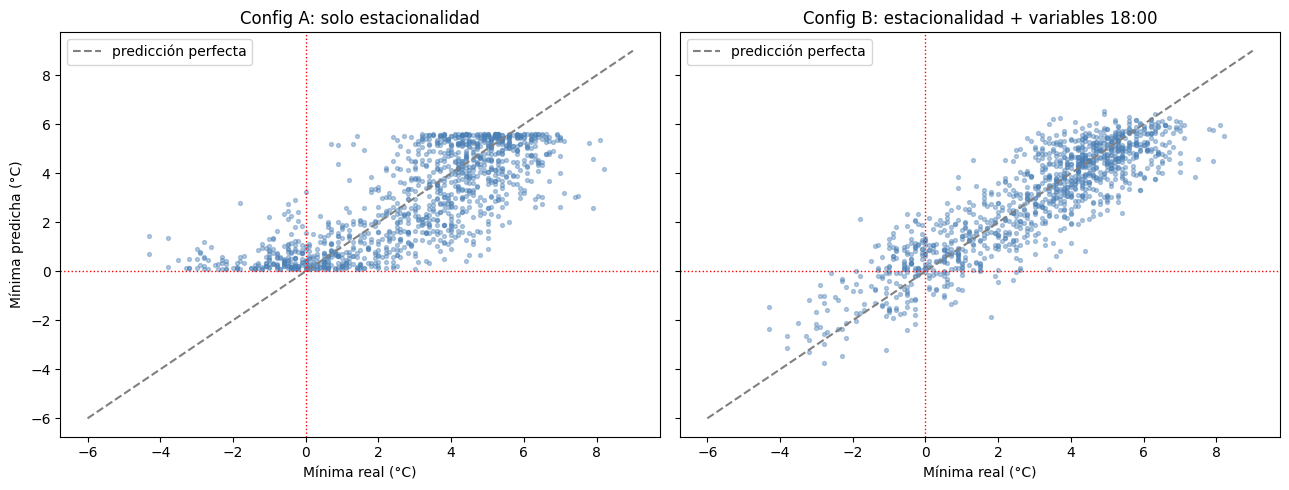

In [19]:
import matplotlib.pyplot as plt

pdf_A = pred_A.select("temp_min_noche", "prediction").toPandas()
pdf_B = pred_B.select("temp_min_noche", "prediction").toPandas()

fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, pdf, titulo in [(axs[0], pdf_A, "Config A: solo estacionalidad"),
                        (axs[1], pdf_B, "Config B: estacionalidad + variables 18:00")]:
    ax.scatter(pdf["temp_min_noche"], pdf["prediction"], s=8, alpha=0.4, color="#4a7fb5")
    ax.plot([-6, 9], [-6, 9], color="gray", linestyle="--", label="predicción perfecta")
    ax.axhline(0, color="red", linestyle=":", linewidth=1)
    ax.axvline(0, color="red", linestyle=":", linewidth=1)
    ax.set_xlabel("Mínima real (°C)")
    ax.set_title(titulo)
    ax.legend()
axs[0].set_ylabel("Mínima predicha (°C)")
plt.tight_layout()
plt.show()

### 4.5 Regularización: tres configuraciones
La regularización penaliza coeficientes grandes para evitar sobreajuste. `regParam` es la fuerza de la penalización; `elasticNetParam` mezcla dos tipos: **0 = Ridge** (L2, encoge los coeficientes), **1 = Lasso** (L1, puede llevar algunos a cero) y **0.5 = Elastic Net** (mezcla). Se usa la Config B escalada.

In [20]:
configs = [
    ("Ridge (reg=0.1, L2)", 0.1, 0.0),
    ("Lasso (reg=0.1, L1)", 0.1, 1.0),
    ("ElasticNet (reg=0.1, 0.5)", 0.1, 0.5),
]

resultados = [res_A, res_B]
modelos_reg = {}

for nombre, reg, en in configs:
    lr = LinearRegression(featuresCol="features_B_esc", labelCol="temp_min_noche", regParam=reg, elasticNetParam=en)
    m = lr.fit(train)
    modelos_reg[nombre] = m
    resultados.append(evaluar(m.transform(test), nombre))

Ridge (reg=0.1, L2): RMSE=1.127 °C | R²=0.782 | MAE=0.882 °C | recall helada=0.522 | precisión helada=0.774
Lasso (reg=0.1, L1): RMSE=1.145 °C | R²=0.775 | MAE=0.897 °C | recall helada=0.473 | precisión helada=0.791
ElasticNet (reg=0.1, 0.5): RMSE=1.134 °C | R²=0.779 | MAE=0.888 °C | recall helada=0.495 | precisión helada=0.778


### 4.6 Coeficientes por configuración
Con Lasso algunos coeficientes pueden llegar a 0: el modelo descarta esa variable.

In [21]:
import pandas as pd

tabla_coef = pd.DataFrame(
    {"B sin regularizar": list(modelo_B.coefficients)} |
    {nombre: list(m.coefficients) for nombre, m in modelos_reg.items()},
    index=predictores_B
).round(3)

tabla_coef

,B sin regularizar,"Ridge (reg=0.1, L2)","Lasso (reg=0.1, L1)","ElasticNet (reg=0.1, 0.5)"
seno,-0.169,-0.167,-0.088,-0.133
coseno,1.042,1.031,1.068,1.048
temp_18,0.284,0.344,0.284,0.331
rocio_18,1.357,1.127,0.997,1.021
hum_18,-0.337,-0.115,0.000,0.000
nub_18,0.366,0.377,0.260,0.315


### 4.7 Gráfico: error de cada configuración (RMSE y MAE)

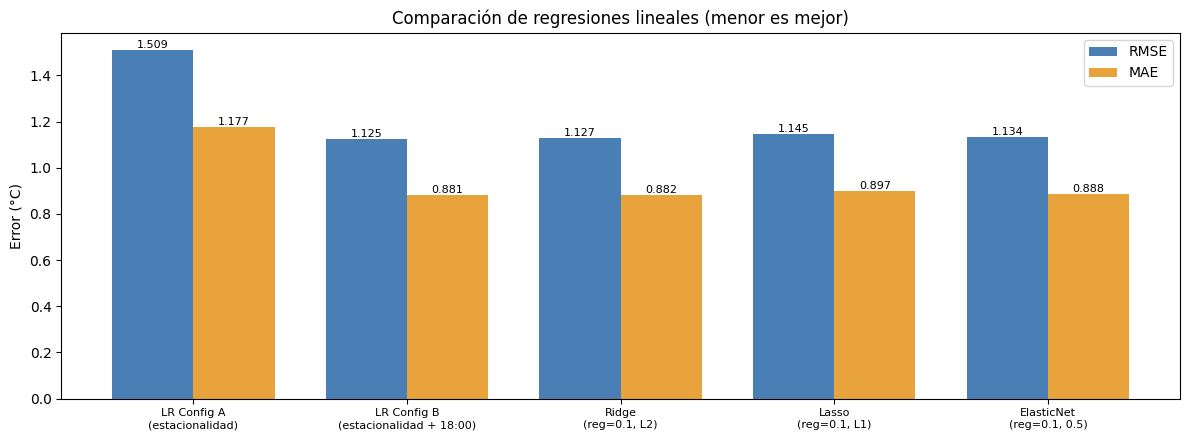

,modelo,RMSE,R2,MAE,recall,precision
0,LR Config A (estacionalidad),1.509,0.609,1.177,0.000,0.000
1,LR Config B (estacionalidad + 18:00),1.125,0.783,0.881,0.533,0.766
2,"Ridge (reg=0.1, L2)",1.127,0.782,0.882,0.522,0.774
3,"Lasso (reg=0.1, L1)",1.145,0.775,0.897,0.473,0.791
4,"ElasticNet (reg=0.1, 0.5)",1.134,0.779,0.888,0.495,0.778


In [22]:
import matplotlib.pyplot as plt
import numpy as np

df_res = pd.DataFrame(resultados)
x = np.arange(len(df_res))
ancho = 0.38

fig, ax = plt.subplots(figsize=(12, 4.5))
b1 = ax.bar(x - ancho/2, df_res["RMSE"], ancho, label="RMSE", color="#4a7fb5")
b2 = ax.bar(x + ancho/2, df_res["MAE"], ancho, label="MAE", color="#e8a33d")
ax.bar_label(b1, fmt="%.3f", fontsize=8)
ax.bar_label(b2, fmt="%.3f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([m.replace(" (", "\n(") for m in df_res["modelo"]], fontsize=8)
ax.set_ylabel("Error (°C)")
ax.set_title("Comparación de regresiones lineales (menor es mejor)")
ax.legend()
plt.tight_layout()
plt.show()

df_res.round(3)

### 4.8 Segundo algoritmo: Random Forest
Un bosque de árboles puede capturar relaciones no lineales y combinaciones de variables que una recta no ve. No necesita predictores escalados, así que usa `features_B`. Se fija `seed=42` para reproducibilidad.

In [23]:
from pyspark.ml.regression import RandomForestRegressor

rf = RandomForestRegressor(
    featuresCol="features_B",
    labelCol="temp_min_noche",
    numTrees=100,
    maxDepth=8,
    seed=42,
)
modelo_rf = rf.fit(train)
pred_rf = modelo_rf.transform(test)

res_rf = evaluar(pred_rf, "Random Forest (100 árboles, prof. 8)")
resultados.append(res_rf)

26/11/20 02:54:36 WARN DAGScheduler: Broadcasting large task binary with size 1065.7 KiB
26/11/20 02:54:36 WARN DAGScheduler: Broadcasting large task binary with size 1973.5 KiB
26/11/20 02:54:37 WARN DAGScheduler: Broadcasting large task binary with size 3.6 MiB
26/11/20 02:54:38 WARN DAGScheduler: Broadcasting large task binary with size 1032.4 KiB
                                                                                

Random Forest (100 árboles, prof. 8): RMSE=1.077 °C | R²=0.801 | MAE=0.839 °C | recall helada=0.560 | precisión helada=0.741


### 4.9 Importancia de variables
Indica cuánto contribuye cada predictor a reducir el error en el bosque. Suma 1.

In [24]:
import pandas as pd

imp = pd.DataFrame({
    "variable": predictores_B,
    "importancia": list(modelo_rf.featureImportances.toArray()),
}).sort_values("importancia", ascending=False)

imp.round(3)

,variable,importancia
1,coseno,0.433
3,rocio_18,0.309
5,nub_18,0.097
4,hum_18,0.069
2,temp_18,0.050
0,seno,0.042


### 4.10 Gráficos: importancia de variables y predicho vs real del Random Forest

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


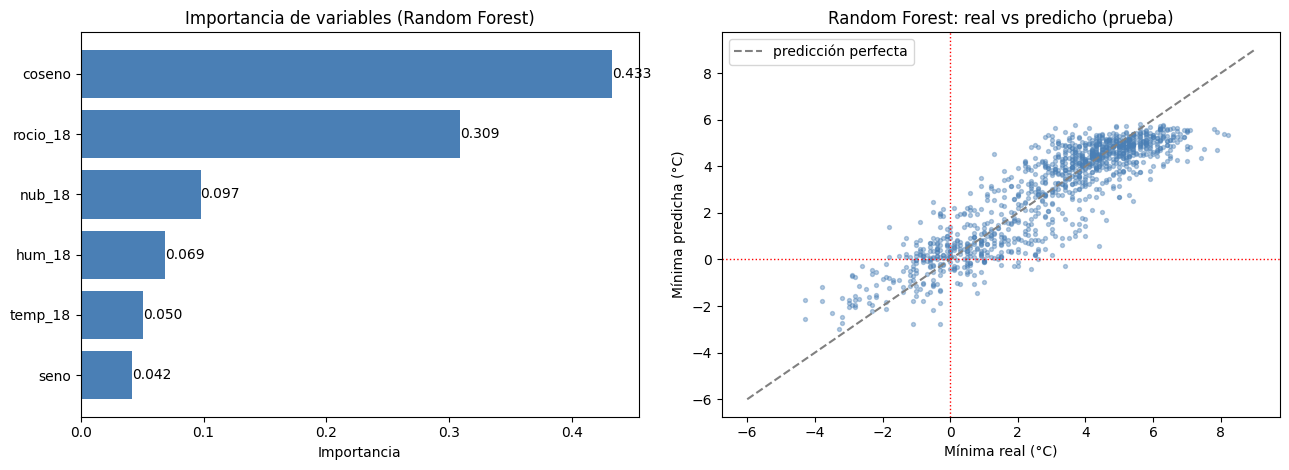

In [25]:
import matplotlib.pyplot as plt

pdf_rf = pred_rf.select("temp_min_noche", "prediction").toPandas()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))

imp_ord = imp.sort_values("importancia")
barras = axs[0].barh(imp_ord["variable"], imp_ord["importancia"], color="#4a7fb5")
axs[0].bar_label(barras, fmt="%.3f")
axs[0].set_title("Importancia de variables (Random Forest)")
axs[0].set_xlabel("Importancia")

axs[1].scatter(pdf_rf["temp_min_noche"], pdf_rf["prediction"], s=8, alpha=0.4, color="#4a7fb5")
axs[1].plot([-6, 9], [-6, 9], color="gray", linestyle="--", label="predicción perfecta")
axs[1].axhline(0, color="red", linestyle=":", linewidth=1)
axs[1].axvline(0, color="red", linestyle=":", linewidth=1)
axs[1].set_xlabel("Mínima real (°C)"); axs[1].set_ylabel("Mínima predicha (°C)")
axs[1].set_title("Random Forest: real vs predicho (prueba)")
axs[1].legend()

plt.tight_layout()
plt.show()

## Fase 5 — Evaluation
### 5.1 Comparación de todos los candidatos

In [26]:
import pandas as pd

df_comp = pd.DataFrame(resultados).sort_values("RMSE").reset_index(drop=True)
df_comp.round(3)

,modelo,RMSE,R2,MAE,recall,precision
0,"Random Forest (100 árboles, prof. 8)",1.077,0.801,0.839,0.560,0.741
1,LR Config B (estacionalidad + 18:00),1.125,0.783,0.881,0.533,0.766
2,"Ridge (reg=0.1, L2)",1.127,0.782,0.882,0.522,0.774
3,"ElasticNet (reg=0.1, 0.5)",1.134,0.779,0.888,0.495,0.778
4,"Lasso (reg=0.1, L1)",1.145,0.775,0.897,0.473,0.791
5,LR Config A (estacionalidad),1.509,0.609,1.177,0.000,0.000


### 5.2 Selección del mejor modelo
Se selecciona por menor RMSE en el conjunto de prueba. Ninguna métrica sola decide: se revisan también R², MAE y, sobre todo, el recall de helada, que es la que importa para la decisión de negocio.

In [27]:
mejor = df_comp.iloc[0]
print("Mejor modelo por RMSE:", mejor["modelo"])
print(f"RMSE={mejor['RMSE']:.3f} °C | R²={mejor['R2']:.3f} | MAE={mejor['MAE']:.3f} °C | recall={mejor['recall']:.3f}")

Mejor modelo por RMSE: Random Forest (100 árboles, prof. 8)
RMSE=1.077 °C | R²=0.801 | MAE=0.839 °C | recall=0.560


### 5.3 Validación de negocio: ¿el error es aceptable para decidir una helada?
**Criterio de aceptación propuesto:** detectar al menos el **80 %** de las noches con helada (recall ≥ 0.80), tolerando falsas alarmas, porque cubrir un cultivo cuesta mucho menos que perderlo por helada.

Con el umbral de decisión estándar (mínima predicha ≤ 0 °C) el recall es solo 0.56. Se analiza qué pasa si se avisa con un **margen**: avisar cuando la mínima predicha sea ≤ `t` °C, con `t` mayor que 0.

In [28]:
import numpy as np

pdf_mejor = pdf_rf.copy()          # predicciones del Random Forest sobre el conjunto de prueba
real_helada = pdf_mejor["temp_min_noche"] <= 0

filas = []
for t in np.arange(-1.0, 3.01, 0.25):
    aviso = pdf_mejor["prediction"] <= t
    tp = (aviso & real_helada).sum()
    fp = (aviso & ~real_helada).sum()
    fn = (~aviso & real_helada).sum()
    recall = tp / (tp + fn)
    precision = tp / (tp + fp) if (tp + fp) else 0
    filas.append({"umbral_aviso_C": round(t, 2), "recall": round(recall, 3),
                  "precision": round(precision, 3), "falsas_alarmas": int(fp),
                  "noches_con_aviso": int(aviso.sum())})

df_umbral = pd.DataFrame(filas)
df_umbral

,umbral_aviso_C,recall,precision,falsas_alarmas,noches_con_aviso
0,-1.00,0.288,0.930,4,57
1,-0.75,0.342,0.926,5,68
2,-0.50,0.402,0.881,10,84
3,-0.25,0.484,0.795,23,112
4,0.00,0.560,0.741,36,139
5,0.25,0.712,0.689,59,190
6,0.50,0.793,0.627,87,233
7,0.75,0.875,0.577,118,279
8,1.00,0.924,0.533,149,319
9,1.25,0.935,0.506,168,340


### 5.4 Gráfico: compromiso entre detectar heladas y evitar falsas alarmas

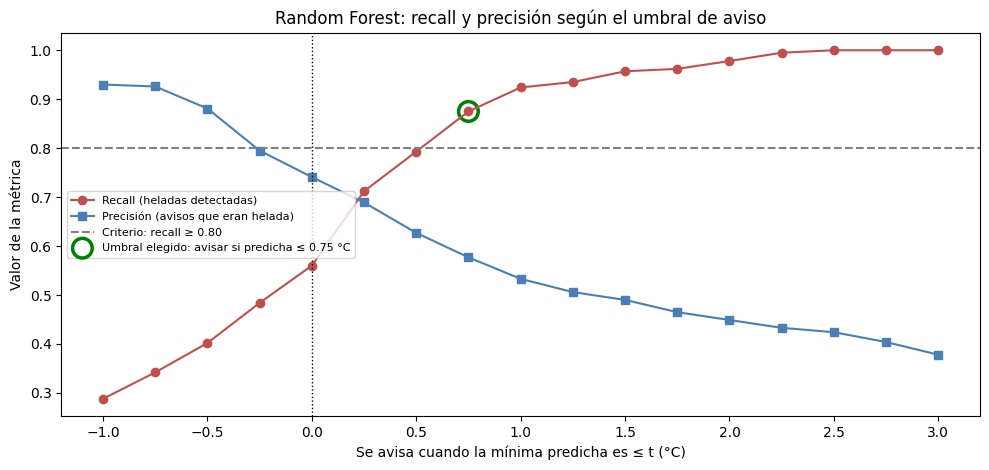

Umbral elegido: {'umbral_aviso_C': np.float64(0.75), 'recall': np.float64(0.875), 'precision': np.float64(0.577), 'falsas_alarmas': np.float64(118.0), 'noches_con_aviso': np.float64(279.0)}


In [29]:
import matplotlib.pyplot as plt

ok = df_umbral[df_umbral["recall"] >= 0.80]
t_elegido = ok.iloc[0] if len(ok) else None

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(df_umbral["umbral_aviso_C"], df_umbral["recall"], marker="o", color="#c0504d", label="Recall (heladas detectadas)")
ax.plot(df_umbral["umbral_aviso_C"], df_umbral["precision"], marker="s", color="#4a7fb5", label="Precisión (avisos que eran helada)")
ax.axhline(0.80, color="gray", linestyle="--", label="Criterio: recall ≥ 0.80")
ax.axvline(0, color="black", linestyle=":", linewidth=1)

if t_elegido is not None:
    ax.scatter(t_elegido["umbral_aviso_C"], t_elegido["recall"], s=200, facecolors="none", edgecolors="green", linewidths=2.5,
               label=f"Umbral elegido: avisar si predicha ≤ {t_elegido['umbral_aviso_C']} °C")

ax.set_xlabel("Se avisa cuando la mínima predicha es ≤ t (°C)")
ax.set_ylabel("Valor de la métrica")
ax.set_title("Random Forest: recall y precisión según el umbral de aviso")
ax.legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()

if t_elegido is not None:
    print("Umbral elegido:", dict(t_elegido))

### 5.5 Conclusión de la validación de negocio
El Random Forest (RMSE 1.077 °C, R² 0.801, MAE 0.839 °C) es el mejor candidato. Con la regla estándar (avisar si la mínima predicha es ≤ 0 °C) detecta solo el 56 % de las heladas, por debajo del criterio del 80 %. Con un margen de aviso de **0.75 °C** el recall sube a **0.875** (161 de 184 heladas del conjunto de prueba) con 118 falsas alarmas en 1 175 noches (10 %). **El modelo cumple el objetivo de negocio con ese margen.**

**Limitación:** el umbral de 0.75 °C se eligió sobre el mismo conjunto de prueba que se usó para evaluar, por lo que el recall real podría ser algo menor; lo correcto es fijarlo con un conjunto de validación aparte.

## Fase 6 — Deployment
### 6.1 Guardar el modelo seleccionado
Se guarda el Random Forest, que es el de mejor desempeño en la comparación. El umbral de aviso (0.75 °C) forma parte de la regla de decisión y se documenta junto al modelo.

In [30]:
ARTIFACTS = "/opt/u1/s04-modelo-heladas/artifacts"

modelo_rf.write().overwrite().save(f"{ARTIFACTS}/modelo_rf_heladas")
print("Modelo guardado en:", f"{ARTIFACTS}/modelo_rf_heladas")

Modelo guardado en: /opt/u1/s04-modelo-heladas/artifacts/modelo_rf_heladas


### 6.2 Cargar el modelo y verificar que da las mismas predicciones

In [31]:
from pyspark.ml.regression import RandomForestRegressionModel

modelo_cargado = RandomForestRegressionModel.load(f"{ARTIFACTS}/modelo_rf_heladas")
pred_cargado = modelo_cargado.transform(test)

dif = pred_rf.select("fecha", "prediction").withColumnRenamed("prediction", "p1") \
    .join(pred_cargado.select("fecha", "prediction").withColumnRenamed("prediction", "p2"), "fecha") \
    .selectExpr("max(abs(p1 - p2)) as diferencia_maxima").collect()[0][0]

print("Diferencia máxima entre predicciones originales y del modelo cargado:", dif)
assert dif < 1e-9, "El modelo cargado no coincide con el original"
print("Control: el modelo guardado reproduce exactamente las predicciones.")

Diferencia máxima entre predicciones originales y del modelo cargado: 0.0
Control: el modelo guardado reproduce exactamente las predicciones.


## Error o hallazgo
### El mejor modelo por RMSE no cumple el objetivo de negocio con la regla estándar

**Qué ocurrió:** el Random Forest ganó la comparación (RMSE 1.077 °C, R² 0.801), pero con la regla "helada si la mínima predicha ≤ 0 °C" detectó solo el 56 % de las heladas. Un buen RMSE no garantizaba una buena decisión.

**Cómo lo identifiqué:** en el gráfico de real vs predicho, las noches más frías quedan por encima de la diagonal (el modelo las subestima: tiende a la media). Convertí la predicción en decisión (helada / no helada) y calculé recall y precisión por umbral.

**Decisión:** avisar cuando la mínima predicha sea ≤ 0.75 °C. Recall 0.875 con 10 % de falsas alarmas, aceptable porque cubrir un cultivo cuesta mucho menos que perderlo. La limitación es que el umbral se eligió sobre el conjunto de prueba; en una versión posterior se fijará con un conjunto de validación.

**Otro resultado:** la regularización (Ridge, Lasso, ElasticNet) no mejoró al modelo lineal: Lasso llevó `hum_18` a 0, y cuanto más penaliza, menor es el recall.

## Reflexión técnica
### ¿Por qué confiar en un único modelo, sin comparar configuraciones ni algoritmos alternativos, es una decisión de riesgo?

Si solo hubiera entrenado el modelo con la fecha (Config A) habría creído que predecir heladas era imposible: su recall fue 0, nunca avisaba. Si solo hubiera entrenado una regresión lineal habría quedado con 0.53 de recall sin saber que un bosque llega a 0.56 y que cambiando el umbral de aviso se llega a 0.875. Comparar me mostró qué variables importan (`rocio_18` y la estacionalidad), que la regularización no ayudaba y que el RMSE por sí solo no decide si el modelo sirve para la decisión del agricultor. Con un único modelo no habría tenido contra qué medir si el resultado era bueno o simplemente el primero que probé.